# A5 / A6 · Scenario ground truth and T-learner uplift baseline

The intervention history is synthetic. Its outcomes follow the documented
effect function in `anchorai.scenario.build` (see docs/SCENARIO.md). This notebook shows the
ground truth is heterogeneous and that the T-learner baseline (input to E3) recovers part of it.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.config import get_settings
from anchorai.features import build_features
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
members = tables["members"]
labels = members.set_index("member_id")
features = build_features(members)
is_train = labels["split"] == "train"
print(len(members), "members;", is_train.sum(), "train /", (~is_train).sum(), "test")

4000 members; 3200 train / 800 test


In [2]:
from anchorai.discovery.scores import load_scores
from anchorai.scenario.build import base_churn

interventions, true_uplift = tables["interventions"], tables["true_uplift"]
scores = load_scores()[["member_id", "segment"]]
by_arm = interventions.assign(arm=interventions["offer_id"].fillna("no contact")).groupby("arm")["stayed"].agg(["size", "mean"]).round(3)
print("treated vs control stay rate:", round(interventions.loc[interventions.treated, "stayed"].mean(), 3), "vs", round(interventions.loc[~interventions.treated, "stayed"].mean(), 3))
by_arm

treated vs control stay rate: 0.719 vs 0.67


,size,mean
arm,,
checkin_message,354,0.678
class_pass,368,0.712
discount_1m,341,0.710
free_pt_session,353,0.776
no contact,984,0.670


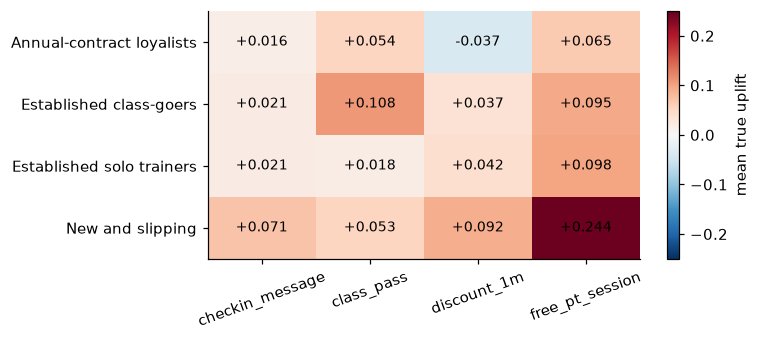

In [3]:
heat = true_uplift.merge(scores, on="member_id").pivot_table(index="segment", columns="offer_id", values="uplift")
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-0.25, vmax=0.25, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=20); ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:+.3f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, label="mean true uplift")
fig.tight_layout(); fig.savefig(FIG / "a5_true_uplift_by_segment.png"); plt.show()
heat.round(3).to_csv(RES / "a5_true_uplift_by_segment.csv")

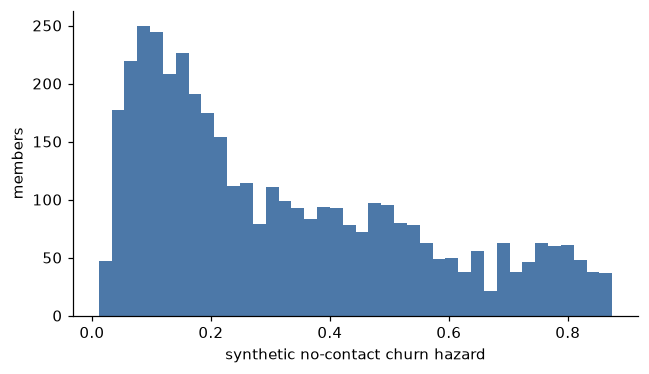

correlation of synthetic hazard with the real churn label: 0.715


In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(base_churn(features), bins=40, color="#4c78a8")
ax.set_xlabel("synthetic no-contact churn hazard"); ax.set_ylabel("members")
fig.tight_layout(); fig.savefig(FIG / "a5_base_hazard.png"); plt.show()
print("correlation of synthetic hazard with the real churn label:", round(np.corrcoef(base_churn(features), labels["churn"])[0, 1], 3))

## T-learner vs ground truth

In [5]:
from scipy.stats import spearmanr
from anchorai.discovery.uplift import t_learner

estimate = t_learner(features, interventions, list(tables["offers"]["offer_id"]), SEED)
joined = true_uplift.merge(estimate, on=["member_id", "offer_id"], suffixes=("_true", "_est"))
recovery = joined.groupby("offer_id").apply(lambda g: pd.Series({
    "spearman": spearmanr(g.uplift_true, g.uplift_est).statistic,
    "true_mean": g.uplift_true.mean(), "est_mean": g.uplift_est.mean()})).round(3)
recovery.loc["all"] = [spearmanr(joined.uplift_true, joined.uplift_est).statistic, joined.uplift_true.mean(), joined.uplift_est.mean()]
recovery.round(3).to_csv(RES / "a6_tlearner_recovery.csv")
recovery.round(3)

,spearman,true_mean,est_mean
offer_id,,,
checkin_message,0.264,0.029,0.024
class_pass,0.337,0.054,0.075
discount_1m,0.273,0.031,0.048
free_pt_session,0.608,0.116,0.107
all,0.392,0.058,0.064


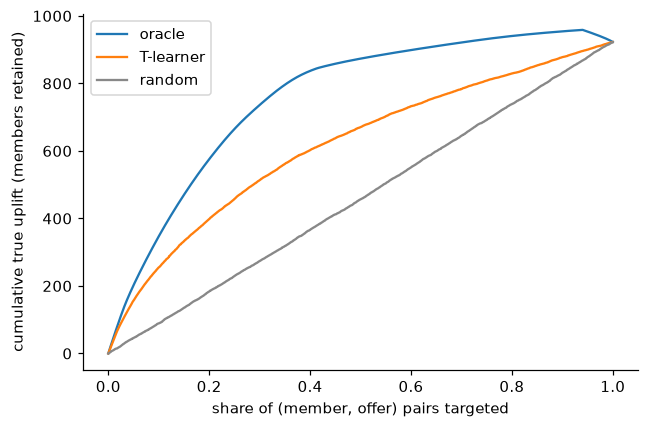

In [6]:
def qini(frame, score):
    order = frame.sort_values(score, ascending=False)
    return np.concatenate([[0], order["uplift_true"].cumsum().to_numpy()])

fig, ax = plt.subplots(figsize=(6, 4))
n = len(joined)
x = np.arange(n + 1) / n
for score, name in (("uplift_true", "oracle"), ("uplift_est", "T-learner")):
    ax.plot(x, qini(joined, score), label=name)
rng = np.random.default_rng(SEED)
ax.plot(x, qini(joined.assign(r=rng.random(n)), "r"), label="random", color="#888")
ax.set_xlabel("share of (member, offer) pairs targeted"); ax.set_ylabel("cumulative true uplift (members retained)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "a6_qini.png"); plt.show()

## Gym events and the no-contact hazard (HANDOFFS #1)

`true_churn` holds the next-month churn probability without contact, before (`base_churn`) and after
(`event_churn`) the gym events, plus one seeded draw (`churned_no_contact`). Real Kaggle labels cannot
react to synthetic events, so this is the outcome E7 measures the knowledge graph against.

In [7]:
from anchorai.scenario.build import EVENT_EFFECTS, base_logit, event_exposure, event_shift, sigmoid

truth = tables["true_churn"].set_index("member_id")
flags = {
    "lost instructor (share >= 0.5)": truth["lost_instructor_share"] >= 0.5,
    "cancelled class": truth["cancelled_share"] > 0,
}
train_churn = labels.loc[is_train, "churn"]
rows = []
for name, flag in flags.items():
    rows.append({
        "signal": name,
        "members": int(flag.sum()),
        "base_churn": truth.loc[flag, "base_churn"].mean(),
        "event_churn": truth.loc[flag, "event_churn"].mean(),
        "within_rise": truth.loc[flag, "event_churn"].mean() / truth.loc[flag, "base_churn"].mean(),
        "lift_vs_all": truth.loc[flag, "event_churn"].mean() / truth["event_churn"].mean(),
        "sampled_lift": truth.loc[flag, "churned_no_contact"].mean() / truth["churned_no_contact"].mean(),
        "real_label_lift_train": train_churn[flag[is_train]].mean() / train_churn.mean(),
    })
event_lift = pd.DataFrame(rows).set_index("signal")
event_lift.round(3).to_csv(RES / "a5_event_lift.csv")
print("EVENT_EFFECTS:", EVENT_EFFECTS)
event_lift.round(3)

EVENT_EFFECTS: {'instructor_left': 1.4, 'class_cancelled': 0.9}


,members,base_churn,event_churn,within_rise,lift_vs_all,sampled_lift,real_label_lift_train
signal,,,,,,,
lost instructor (share >= 0.5),186,0.262,0.472,1.799,1.409,1.338,0.632
cancelled class,170,0.253,0.334,1.320,0.997,0.915,0.722


**Sensitivity.** The same lost-instructor members under scaled event effects (0 = no effect, 1 = default).

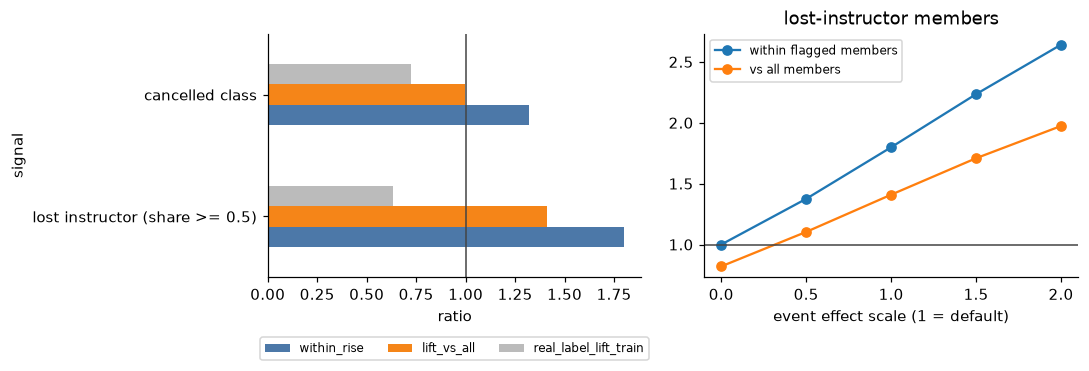

,within_rise,lift_vs_all
scale,,
0.0,1.000,0.820
0.5,1.375,1.104
1.0,1.799,1.409
1.5,2.235,1.709
2.0,2.641,1.973


In [8]:
exposure = event_exposure(tables["attendance"], tables["classes"], tables["events"])
logit = base_logit(features)
instructor = flags["lost instructor (share >= 0.5)"].reindex(features.index)
sensitivity = []
for scale in (0.0, 0.5, 1.0, 1.5, 2.0):
    effects = {k: v * scale for k, v in EVENT_EFFECTS.items()}
    hazard = pd.Series(sigmoid((logit + event_shift(exposure, features.index, effects)).to_numpy()), index=features.index)
    sensitivity.append({"scale": scale,
                        "within_rise": hazard[instructor].mean() / sigmoid(logit[instructor].to_numpy()).mean(),
                        "lift_vs_all": hazard[instructor].mean() / hazard.mean()})
sensitivity = pd.DataFrame(sensitivity).set_index("scale")
sensitivity.round(3).to_csv(RES / "a5_event_sensitivity.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
event_lift[["within_rise", "lift_vs_all", "real_label_lift_train"]].plot.barh(ax=axes[0], color=["#4c78a8", "#f58518", "#bbbbbb"])
axes[0].axvline(1, color="#444", lw=1); axes[0].set_xlabel("ratio"); axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
axes[1].plot(sensitivity.index, sensitivity["within_rise"], marker="o", label="within flagged members")
axes[1].plot(sensitivity.index, sensitivity["lift_vs_all"], marker="o", label="vs all members")
axes[1].axhline(1, color="#444", lw=1); axes[1].set_xlabel("event effect scale (1 = default)"); axes[1].legend(fontsize=8)
axes[1].set_title("lost-instructor members")
fig.tight_layout(); fig.savefig(FIG / "a5_event_lift.png"); plt.show()
sensitivity.round(3)

**Reading.** On real labels the flagged members churn *less* than average, because class-goers
are lower-risk to begin with. That selection effect stays in the scenario (scale 0 gives lift below
1). With the documented event effects, members who lost their instructor face a much higher hazard
than before the event, which the churn model cannot see. That gap is what the knowledge graph adds.

**Reading.** The ground truth varies strongly by segment and offer (PT sessions for new,
slipping members; class passes for class-goers; discounts backfire on annual contracts). The
T-learner ranks pairs far better than random but well below the oracle; that gap is what B's
CBR estimator is compared on in E3.